# Condition comparison: paired analysis across 20 replications

Reads `data/generated/simulation_replications.csv` (20 seeded replications x
5 conditions) and runs paired comparisons across five condition pairs on
three outcome metrics: true-basis utilisation, average cases per session,
and session overrun rate.

In [13]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

Path("notebooks/figures").mkdir(parents=True, exist_ok=True)

Working directory: c:\Users\Peter\OneDrive\Desktop\Masters Project


In [14]:
replications = pd.read_csv("data/generated/simulation_replications.csv")

metrics = [
    ("utilisation_true_pct", "True-basis utilisation (%)"),
    ("avg_cases_per_session", "Avg cases per session"),
    ("overrun_rate_pct", "Session overrun rate (%)"),
    ("mean_overrun_minutes_all", "Mean overrun minutes (all sessions)"),
    ("mean_overrun_minutes_when_overrun", "Mean overrun minutes (when overrun occurs)"),
]

wide = {
    metric: replications.pivot(index="seed", columns="condition", values=metric)
    for metric, _ in metrics
}

comparisons = [
    ("C0: Traditional", "C1: Predicted, no gap-fill", "Baseline vs predicted"),
    ("C1: Predicted, no gap-fill", "C3: Oracle, no gap-fill", "Predicted vs oracle (prediction-accuracy effect)"),
    ("C1: Predicted, no gap-fill", "C2: Predicted, gap-fill", "Predicted: gap-fill effect"),
    ("C3: Oracle, no gap-fill", "C4: Oracle, gap-fill", "Oracle: gap-fill effect"),
    ("C0: Traditional", "C4: Oracle, gap-fill", "Baseline vs best case (ceiling)"),
]

In [15]:
def paired_stats(wide_metric_df, cond_a, cond_b):
    a = wide_metric_df[cond_a].values
    b = wide_metric_df[cond_b].values
    n = len(a)

    mean_a, mean_b = a.mean(), b.mean()
    ci_a = stats.t.interval(0.95, n - 1, loc=mean_a, scale=stats.sem(a)) if a.std(ddof=1) > 0 else (mean_a, mean_a)
    ci_b = stats.t.interval(0.95, n - 1, loc=mean_b, scale=stats.sem(b)) if b.std(ddof=1) > 0 else (mean_b, mean_b)

    diff = b - a
    mean_diff = diff.mean()
    diff_sd = diff.std(ddof=1)

    if diff_sd > 0:
        diff_ci = stats.t.interval(0.95, n - 1, loc=mean_diff, scale=stats.sem(diff))
        t_stat, t_p = stats.ttest_rel(b, a)
        try:
            _, w_p = stats.wilcoxon(b, a)
        except ValueError:
            w_p = np.nan
        cohens_d = mean_diff / diff_sd
    else:
        diff_ci = (mean_diff, mean_diff)
        t_stat, t_p, w_p, cohens_d = np.nan, np.nan, np.nan, np.nan

    return {
        "mean_a": mean_a, "ci_a_low": ci_a[0], "ci_a_high": ci_a[1],
        "mean_b": mean_b, "ci_b_low": ci_b[0], "ci_b_high": ci_b[1],
        "mean_diff": mean_diff, "diff_ci_low": diff_ci[0], "diff_ci_high": diff_ci[1],
        "t_stat": t_stat, "t_pvalue": t_p, "wilcoxon_pvalue": w_p,
        "cohens_d": cohens_d, "n": n,
    }

In [16]:
def plot_comparison(ax, wide_metric_df, cond_a, cond_b, metric_label):
    a = wide_metric_df[cond_a].values
    b = wide_metric_df[cond_b].values
    n = len(a)

    label_a = cond_a.split(":")[0]
    label_b = cond_b.split(":")[0]

    ax.boxplot([a, b], positions=[0, 1], widths=0.5, tick_labels=[label_a, label_b])

    mean_a, mean_b = a.mean(), b.mean()
    sem_a, sem_b = stats.sem(a), stats.sem(b)
    ci_a = stats.t.interval(0.95, n - 1, loc=mean_a, scale=sem_a) if a.std(ddof=1) > 0 else (mean_a, mean_a)
    ci_b = stats.t.interval(0.95, n - 1, loc=mean_b, scale=sem_b) if b.std(ddof=1) > 0 else (mean_b, mean_b)
    err_a, err_b = mean_a - ci_a[0], mean_b - ci_b[0]

    ax.plot([0, 1], [mean_a, mean_b], color="red", linestyle="--", linewidth=1, zorder=4)
    ax.errorbar([0, 1], [mean_a, mean_b], yerr=[[err_a, err_b], [err_a, err_b]],
                fmt="o", color="red", capsize=5, zorder=5, label="Mean (95% CI)")

    ax.set_ylabel(metric_label)
    ax.legend(fontsize=8, loc="best")

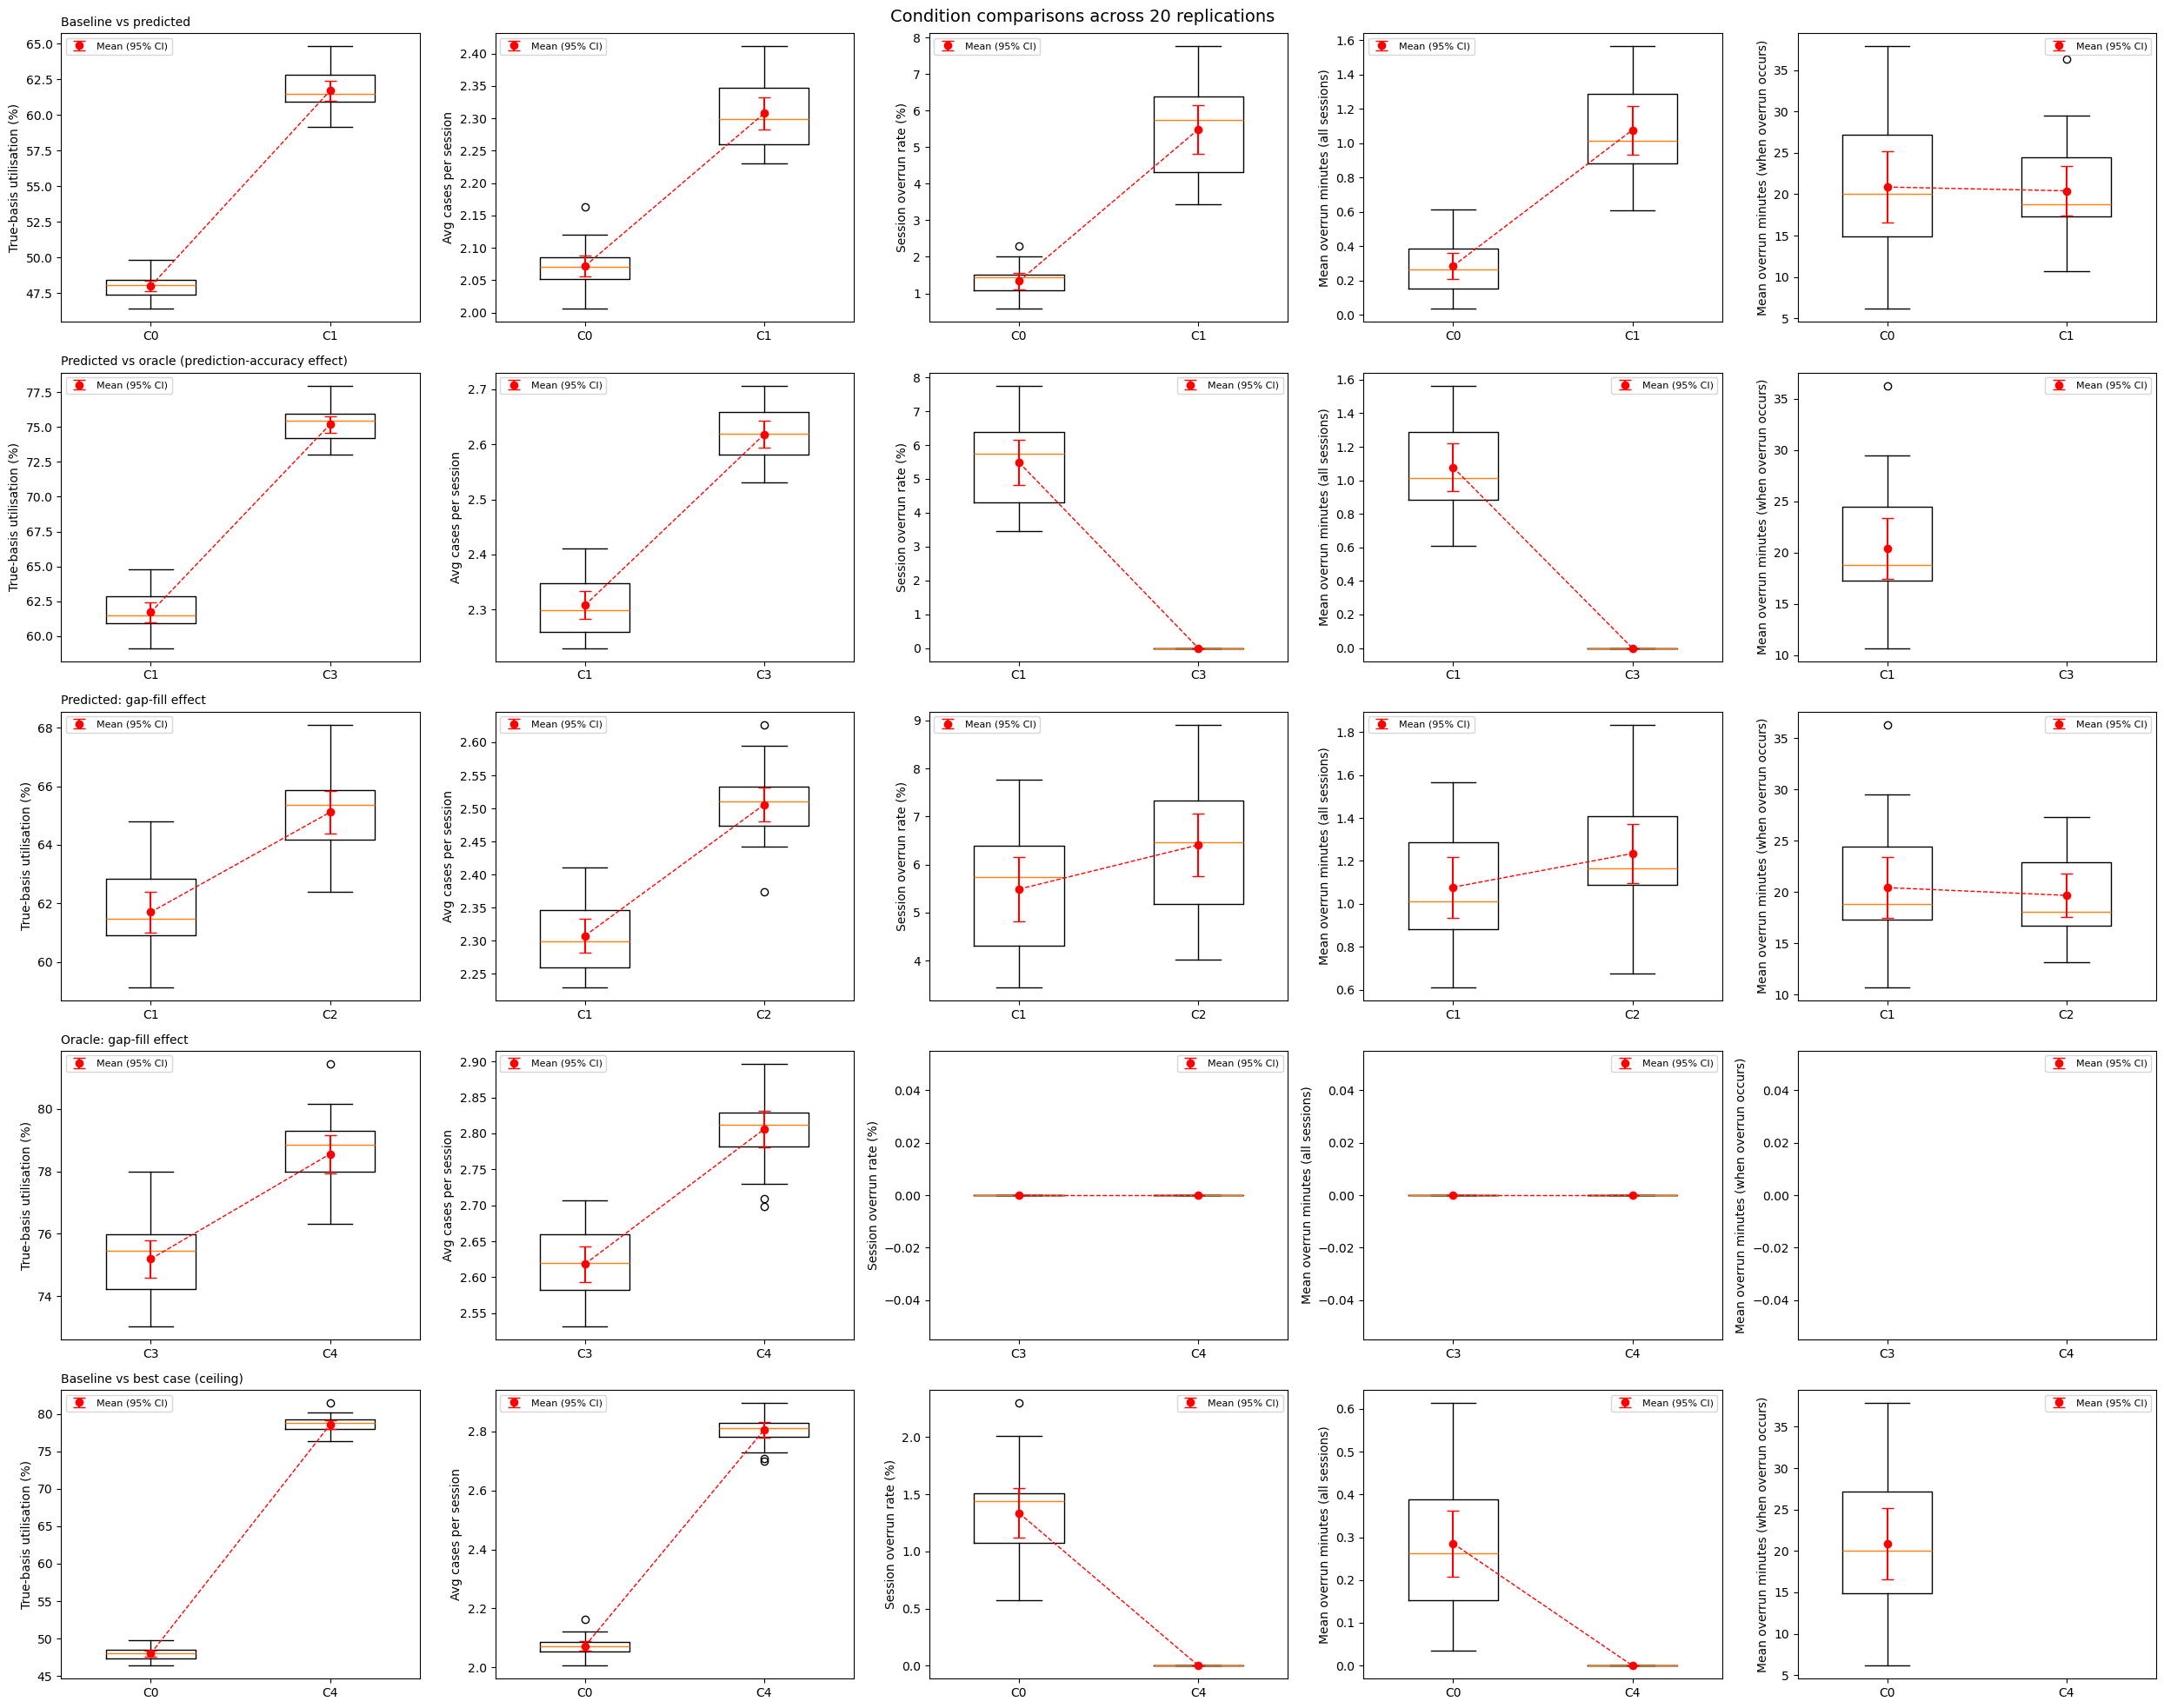

,comparison,metric,condition_a,condition_b,mean_a,ci_a_low,ci_a_high,mean_b,ci_b_low,ci_b_high,mean_diff,diff_ci_low,diff_ci_high,t_stat,t_pvalue,wilcoxon_pvalue,cohens_d,n
0,Baseline vs predicted,utilisation_true_pct,C0: Traditional,"C1: Predicted, no gap-fill",47.986599,47.609541,48.363658,61.699321,61.003742,62.394901,13.712722,13.132668,14.292776,49.480004,1.515197e-21,0.000002,11.064065,20
1,Baseline vs predicted,avg_cases_per_session,C0: Traditional,"C1: Predicted, no gap-fill",2.071695,2.055596,2.087795,2.307615,2.282457,2.332773,0.235920,0.218202,0.253638,27.869091,7.123719e-17,0.000088,6.231718,20
2,Baseline vs predicted,overrun_rate_pct,C0: Traditional,"C1: Predicted, no gap-fill",1.336207,1.116844,1.555570,5.488506,4.822615,6.154396,4.152299,3.520783,4.783815,13.761905,2.479630e-11,0.000088,3.077255,20
3,Baseline vs predicted,mean_overrun_minutes_all,C0: Traditional,"C1: Predicted, no gap-fill",0.285374,0.208625,0.362122,1.077759,0.935892,1.219625,0.792385,0.664534,0.920236,12.971973,6.877641e-11,0.000002,2.900621,20
4,Baseline vs predicted,mean_overrun_minutes_when_overrun,C0: Traditional,"C1: Predicted, no gap-fill",20.873780,16.555118,25.192442,20.416160,17.445007,23.387313,-0.457620,-5.486485,4.571245,-0.190462,8.509670e-01,0.927279,-0.042589,20
5,Predicted vs oracle (prediction-accuracy effect),utilisation_true_pct,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",61.699321,61.003742,62.394901,75.193715,74.597767,75.789663,13.494394,13.104545,13.884243,72.448829,1.122578e-24,0.000002,16.200051,20
6,Predicted vs oracle (prediction-accuracy effect),avg_cases_per_session,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",2.307615,2.282457,2.332773,2.618247,2.593703,2.642792,0.310632,0.299681,0.321583,59.369951,4.854222e-23,0.000088,13.275525,20
7,Predicted vs oracle (prediction-accuracy effect),overrun_rate_pct,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",5.488506,4.822615,6.154396,0.000000,0.000000,0.000000,-5.488506,-6.154396,-4.822615,-17.251443,4.593292e-13,0.000087,-3.857540,20
8,Predicted vs oracle (prediction-accuracy effect),mean_overrun_minutes_all,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",1.077759,0.935892,1.219625,0.000000,0.000000,0.000000,-1.077759,-1.219625,-0.935892,-15.900684,1.964949e-12,0.000002,-3.555501,20
9,Predicted vs oracle (prediction-accuracy effect),mean_overrun_minutes_when_overrun,"C1: Predicted, no gap-fill","C3: Oracle, no gap-fill",20.416160,17.445007,23.387313,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20


In [17]:
fig, axes = plt.subplots(len(comparisons), len(metrics),
                          figsize=(5 * len(metrics), 4 * len(comparisons)))

results_rows = []

for i, (cond_a, cond_b, comp_label) in enumerate(comparisons):
    for j, (metric, metric_label) in enumerate(metrics):
        wdf = wide[metric]
        row = paired_stats(wdf, cond_a, cond_b)
        results_rows.append({
            "comparison": comp_label,
            "metric": metric,
            "condition_a": cond_a,
            "condition_b": cond_b,
            **row,
        })

        ax = axes[i, j]
        plot_comparison(ax, wdf, cond_a, cond_b, metric_label)
        if j == 0:
            ax.set_title(comp_label, fontsize=10, loc="left")

fig.suptitle("Condition comparisons across 20 replications", fontsize=14)
fig.tight_layout()
fig.savefig("notebooks/figures/condition_comparisons.png", dpi=150, bbox_inches="tight")
plt.show()

results_df = pd.DataFrame(results_rows)
results_df.to_csv("data/generated/comparison_results.csv", index=False)
results_df

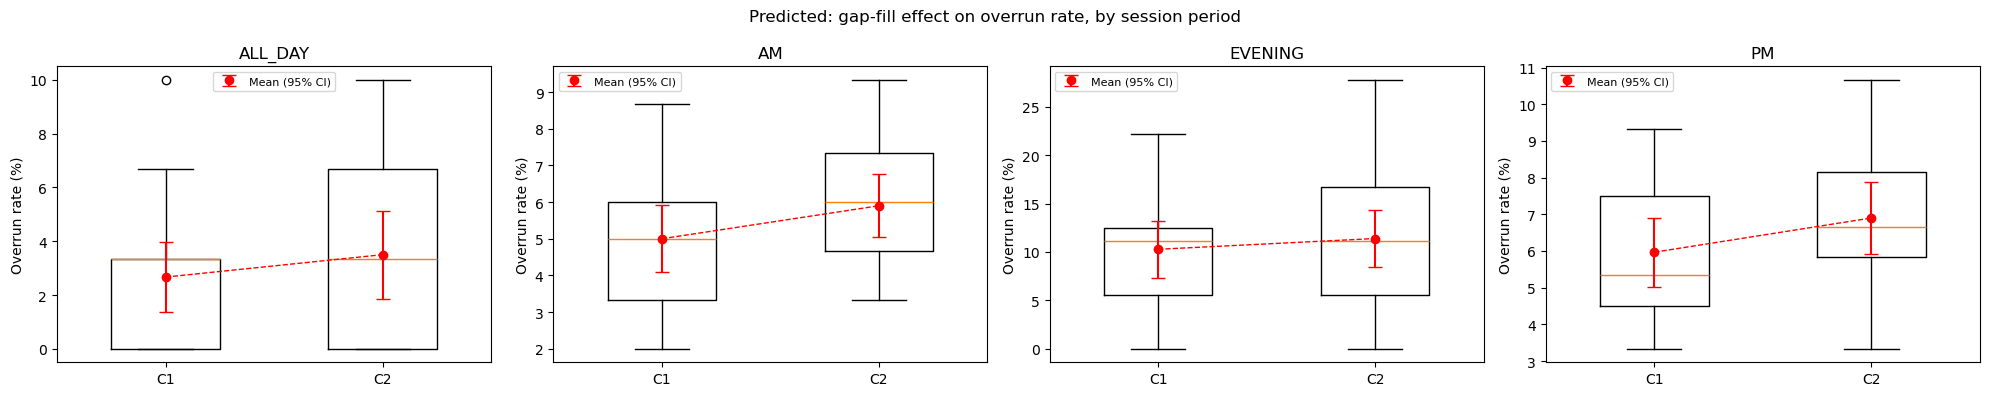

,period,comparison,mean_a,ci_a_low,ci_a_high,mean_b,ci_b_low,ci_b_high,mean_diff,diff_ci_low,diff_ci_high,t_stat,t_pvalue,wilcoxon_pvalue,cohens_d,n
0,ALL_DAY,Baseline vs predicted,0.333333,-0.146839,0.813506,2.666667,1.366353,3.966980,2.333333,1.083244,3.583423,3.906699,9.481909e-04,0.003159,0.873564,20
1,ALL_DAY,Predicted vs oracle (prediction-accuracy effect),2.666667,1.366353,3.966980,0.000000,0.000000,0.000000,-2.666667,-3.966980,-1.366353,-4.292347,3.931739e-04,0.001316,-0.959798,20
2,ALL_DAY,Predicted: gap-fill effect,2.666667,1.366353,3.966980,3.500000,1.861852,5.138148,0.833333,-0.284208,1.950874,1.560736,1.350881e-01,0.076881,0.348991,20
3,ALL_DAY,Oracle: gap-fill effect,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,20
4,ALL_DAY,Baseline vs best case (ceiling),0.333333,-0.146839,0.813506,0.000000,0.000000,0.000000,-0.333333,-0.813506,0.146839,-1.452966,1.625500e-01,0.157299,-0.324893,20
5,AM,Baseline vs predicted,0.700000,0.388401,1.011599,5.000000,4.086129,5.913871,4.300000,3.408981,5.191019,10.100799,4.476772e-09,0.000087,2.258607,20
6,AM,Predicted vs oracle (prediction-accuracy effect),5.000000,4.086129,5.913871,0.000000,0.000000,0.000000,-5.000000,-5.913871,-4.086129,-11.451418,5.686740e-10,0.000085,-2.560615,20
7,AM,Predicted: gap-fill effect,5.000000,4.086129,5.913871,5.900000,5.045377,6.754623,0.900000,0.307355,1.492645,3.178497,4.946858e-03,0.012732,0.710734,20
8,AM,Oracle: gap-fill effect,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,20
9,AM,Baseline vs best case (ceiling),0.700000,0.388401,1.011599,0.000000,0.000000,0.000000,-0.700000,-1.011599,-0.388401,-4.701934,1.552433e-04,0.001167,-1.051384,20


In [18]:
by_period = pd.read_csv("data/generated/simulation_replications_by_period.csv")
periods = sorted(by_period["period"].unique())

period_results_rows = []
for period in periods:
    period_df = by_period[by_period["period"] == period]
    period_wide = period_df.pivot(index="seed", columns="condition", values="overrun_rate_pct")
    for cond_a, cond_b, comp_label in comparisons:
        row = paired_stats(period_wide, cond_a, cond_b)
        period_results_rows.append({"period": period, "comparison": comp_label, **row})

period_results_df = pd.DataFrame(period_results_rows)
period_results_df.to_csv("data/generated/comparison_results_by_period.csv", index=False)

fig, axes = plt.subplots(1, len(periods), figsize=(5 * len(periods), 4))
for ax, period in zip(axes, periods):
    period_df = by_period[by_period["period"] == period]
    period_wide = period_df.pivot(index="seed", columns="condition", values="overrun_rate_pct")
    plot_comparison(ax, period_wide, "C1: Predicted, no gap-fill", "C2: Predicted, gap-fill", "Overrun rate (%)")
    ax.set_title(period)
fig.suptitle("Predicted: gap-fill effect on overrun rate, by session period")
fig.tight_layout()
fig.savefig("notebooks/figures/overrun_by_period.png", dpi=150, bbox_inches="tight")
plt.show()

period_results_df

In [ ]:
import numpy as np
import statsmodels.formula.api as smf

session_level = pd.read_csv("data/generated/simulation_session_level.csv")
session_level["overrun"] = session_level["overrun"].astype(int)

logit_model = smf.logit("overrun ~ patients_booked + C(condition)", data=session_level).fit()
print(logit_model.summary())
print(f"\nMcFadden's pseudo R-squared: {logit_model.prsquared:.4f}")
print("\nOdds ratios:")
print(np.exp(logit_model.params))

conditions_list = sorted(session_level["condition"].unique())
colors = plt.cm.tab10.colors
case_range = np.arange(session_level["patients_booked"].min(), session_level["patients_booked"].max() + 1)

fig, ax = plt.subplots(figsize=(7, 5))
for i, cond in enumerate(conditions_list):
    pred_df = pd.DataFrame({"patients_booked": case_range, "condition": cond})
    pred_probs = logit_model.predict(pred_df)
    ax.plot(case_range, pred_probs, label=f"{cond} (fitted)", color=colors[i], linewidth=2)

    observed = session_level[session_level["condition"] == cond].groupby("patients_booked")["overrun"].mean()
    ax.scatter(observed.index, observed.values, color=colors[i], alpha=0.6, marker="o", s=30)

ax.set_xlabel("Patients booked in session")
ax.set_ylabel("P(session overrun)")
ax.set_title(f"Logistic regression: predicted overrun probability\nMcFadden's pseudo R² = {logit_model.prsquared:.3f}")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("notebooks/figures/logit_overrun_probability.png", dpi=150, bbox_inches="tight")
plt.show()

Optimization terminated successfully.
         Current function value: 0.170364
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                overrun   No. Observations:                20880
Model:                          Logit   Df Residuals:                    20876
Method:                           MLE   Df Model:                            3
Date:                Wed, 16 Sep 2026   Pseudo R-squ.:                 0.05767
Time:                        12:02:42   Log-Likelihood:                -3557.2
converged:                       True   LL-Null:                       -3774.9
Covariance Type:            nonrobust   LLR p-value:                 4.712e-94
                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                   

In [ ]:
overrun_only = session_level[session_level["overrun"] == 1]

severity_model = smf.ols("overrun_minutes ~ patients_booked + C(condition)", data=overrun_only).fit()
print(severity_model.summary())
print(f"\nR-squared: {severity_model.rsquared:.4f}")
print(f"Adjusted R-squared: {severity_model.rsquared_adj:.4f}")

fitted = severity_model.fittedvalues
actual = overrun_only["overrun_minutes"]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(fitted, actual, alpha=0.4, s=20)
lims = [min(fitted.min(), actual.min()), max(fitted.max(), actual.max())]
ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="Perfect fit")
ax.set_xlabel("Predicted overrun minutes")
ax.set_ylabel("Actual overrun minutes")
ax.set_title(f"Severity model: actual vs predicted\nR² = {severity_model.rsquared:.3f}, Adj. R² = {severity_model.rsquared_adj:.3f}")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("notebooks/figures/severity_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for i, cond in enumerate(sorted(overrun_only["condition"].unique())):
    subset = overrun_only[overrun_only["condition"] == cond]
    ax.scatter(subset["patients_booked"], subset["overrun_minutes"], alpha=0.4, s=20, color=colors[i], label=cond)

    cond_range = np.arange(subset["patients_booked"].min(), subset["patients_booked"].max() + 1)
    pred_df = pd.DataFrame({"patients_booked": cond_range, "condition": cond})
    fitted_line = severity_model.predict(pred_df)
    ax.plot(cond_range, fitted_line, color=colors[i], linewidth=2)

ax.set_xlabel("Patients booked in session")
ax.set_ylabel("Overrun minutes (when overrun occurs)")
ax.set_title("Severity model: overrun minutes vs cases booked, by condition")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("notebooks/figures/severity_by_cases_and_condition.png", dpi=150, bbox_inches="tight")
plt.show()

                            OLS Regression Results                            
Dep. Variable:        overrun_minutes   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.017
Method:                 Least Squares   F-statistic:                     6.238
Date:                Wed, 16 Sep 2026   Prob (F-statistic):           0.000341
Time:                        12:02:51   Log-Likelihood:                -3896.9
No. Observations:                 921   AIC:                             7802.
Df Residuals:                     917   BIC:                             7821.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------